# Q3. Who are the valuable customers, and do they come back?

**Decision it informs:** where retention spend should go.

**Scope:** valid orders, January 2015 to September 2017. RFM is scored as of 1 October 2017.

**Method:** RFM quintile scores grouped into six segments; a monthly cohort retention matrix; then an
out-of-time check that the segments actually predict who buys next, because retention money is only well spent
on a segmentation that predicts behaviour.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display

from scdd.db import connect, q, run_analysis
from scdd import style
from scdd.stats import wilson_ci, cramers_v, auc, save_findings

style.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = connect()

## 1. RFM segments
Sources: `sql/analysis/p4_rfm_segments.sql` (one row per customer) and `sql/analysis/p4_segment_summary.sql`.

| Segment | Rule (R, F, M are quintile scores, 5 = best) |
|---|---|
| Champions | R ≥ 4 and mean(F, M) ≥ 4 |
| Loyal | R ≥ 3 and mean(F, M) ≥ 3 |
| New & promising | R ≥ 4, lower F/M |
| At risk | R ≤ 2 and mean(F, M) ≥ 3.5 |
| Hibernating | R ≤ 2 and mean(F, M) < 2.5 |
| Needs attention | everyone else |

In [2]:
rfm = run_analysis("p4_rfm_segments.sql", con)
seg = run_analysis("p4_segment_summary.sql", con)
print(f"{len(rfm):,} customers with a valid order in the window")
seg

12,296 customers with a valid order in the window


,rfm_segment,customers,customer_share,revenue,revenue_share,median_recency_days,avg_orders,avg_revenue
0,Champions,2290,0.1862,"8,781,141.9700",0.2980,49.0000,6.8249,"3,834.5598"
1,Loyal,2653,0.2158,"7,648,062.1600",0.2596,125.0000,5.3076,"2,882.7976"
2,At risk,1386,0.1127,"4,610,827.0400",0.1565,296.0000,5.8304,"3,326.7150"
3,Needs attention,1998,0.1625,"3,573,954.5800",0.1213,213.5000,3.4935,"1,788.7661"
4,Hibernating,2475,0.2013,"2,677,422.8200",0.0909,426.0000,2.2509,"1,081.7870"
5,New & promising,1494,0.1215,"2,172,335.6000",0.0737,54.0000,3.0201,"1,454.0399"


## 2. Cohort retention
Source: `sql/analysis/p4_cohort_retention.sql`. Retention at month *k* = share of a cohort with a valid order in
the *k*-th month after its first. Most customers were acquired in 2015, so later cohorts are small.

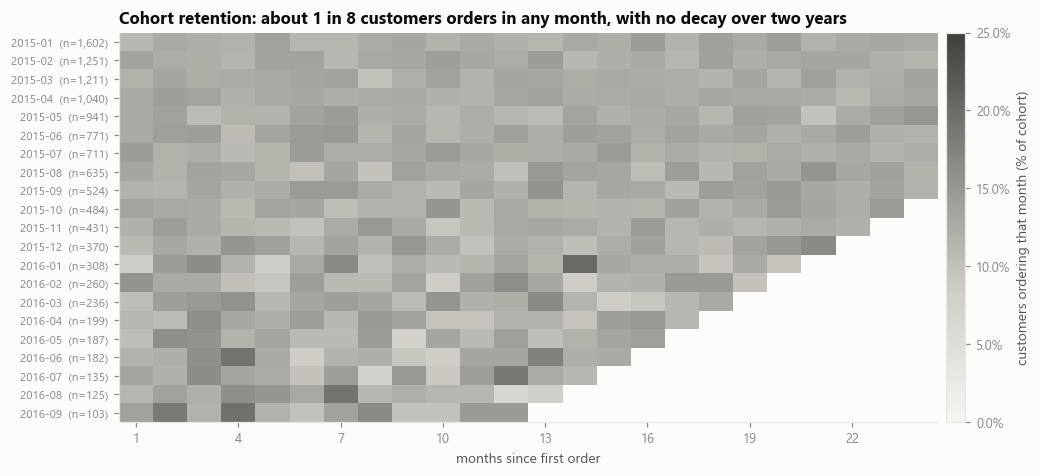

In [3]:
coh = run_analysis("p4_cohort_retention.sql", con)
piv = coh.pivot(index="cohort_month", columns="month_index", values="retention")
sizes = coh.groupby("cohort_month").cohort_size.first()
show = piv.loc[sizes[sizes >= 100].index, 1:24]
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(show.values, cmap=style.GREY_RAMP, vmin=0, vmax=0.25, aspect="auto")
ax.set_yticks(range(len(show)), [d.strftime("%Y-%m") + f"  (n={sizes[d]:,})" for d in show.index], fontsize=7.5)
ax.set_xticks(range(0, show.shape[1], 3), [str(c) for c in show.columns[::3]])
ax.set_xlabel("months since first order"); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, format=plt.matplotlib.ticker.PercentFormatter(1.0))
cb.set_label("customers ordering that month (% of cohort)")
ax.set_title("Cohort retention: about 1 in 8 customers orders in any month, with no decay over two years")
style.save(fig, "q3_cohort_retention")
plt.show()

In [4]:
m3 = run_analysis("p4_month3_retention.sql", con).iloc[0]
m3_ci = wilson_ci(m3.active_in_month_3, m3.cohort_customers)
long = coh[(coh.month_index >= 1) & (coh.month_index <= 24) & (coh.cohort_month <= pd.Timestamp("2016-06-01"))]
slope = smf.wls("retention ~ month_index", long, weights=long.cohort_size).fit()
print(f"Month-3 retention (cohorts Jan 2015 - Jun 2017): {m3.month3_retention:.1%} "
      f"(95% CI {m3_ci[0]:.1%} to {m3_ci[1]:.1%}; {int(m3.active_in_month_3):,} of {int(m3.cohort_customers):,})")
print(f"Retention trend over months 1-24: {slope.params['month_index'] * 100:+.3f} pts per month, p = {slope.pvalues['month_index']:.2f}")

Month-3 retention (cohorts Jan 2015 - Jun 2017): 12.7% (95% CI 12.1% to 13.3%; 1,553 of 12,224)
Retention trend over months 1-24: +0.008 pts per month, p = 0.43


## 3. Does RFM predict who buys next?
Source: `sql/analysis/p4_rfm_validation.sql`. Score every customer on data before 1 April 2017, then look at the
next six months (April to September 2017). If RFM is useful for targeting retention spend, Champions and Loyal
customers should buy more often than Hibernating ones.

In [5]:
val = run_analysis("p4_rfm_validation.sql", con)
cis = [wilson_ci(r.share_ordering_next_6m * r.customers, r.customers) for r in val.itertuples()]
val["ci_low"], val["ci_high"] = zip(*cis)
val

,rfm_segment,customers,share_ordering_next_6m,next_6m_revenue_per_customer,past_revenue_per_customer,ci_low,ci_high
0,Champions,2262,0.5420,436.3980,"3,308.4793",0.5214,0.5624
1,At risk,1299,0.5651,457.3960,"2,742.2207",0.5379,0.5918
2,Loyal,2662,0.5443,441.5564,"2,371.7563",0.5254,0.5632
3,Needs attention,2017,0.5687,466.1497,"1,426.9136",0.5469,0.5901
4,New & promising,1413,0.5534,448.1379,"1,108.0963",0.5274,0.5792
5,Hibernating,2464,0.5552,452.3491,838.6422,0.5355,0.5747


In [6]:
cust = q("""
    WITH c AS (
        SELECT customer_key, max(order_date) AS last_order_date, count(DISTINCT order_id) AS frequency,
               sum(item_total) AS monetary
        FROM fact_order_items WHERE is_valid_order AND order_date < DATE '2017-04-01' GROUP BY 1
    ), nxt AS (
        SELECT DISTINCT customer_key FROM fact_order_items
        WHERE is_valid_order AND order_date >= DATE '2017-04-01' AND order_date < DATE '2017-10-01'
    )
    SELECT c.*, date_diff('day', last_order_date, DATE '2017-04-01') AS recency_days,
           nxt.customer_key IS NOT NULL AS ordered_next_6m
    FROM c LEFT JOIN nxt USING (customer_key)
""", con)
ct = pd.crosstab(val.rfm_segment.repeat(1), [0])  # placeholder to keep pandas quiet
seg_ct = np.array([[r.share_ordering_next_6m * r.customers, (1 - r.share_ordering_next_6m) * r.customers] for r in val.itertuples()])
chi2, p_seg, _, _ = stats.chi2_contingency(seg_ct)
aucs = {
    "recency (more recent = higher)": auc(-cust.recency_days.values, cust.ordered_next_6m.values),
    "frequency": auc(cust.frequency.values, cust.ordered_next_6m.values),
    "monetary": auc(cust.monetary.values, cust.ordered_next_6m.values),
}
print(f"Chi-square across the six segments: p = {p_seg:.2f}")
for k, v in aucs.items():
    print(f"AUC for predicting 'orders in the next 6 months' from {k}: {v:.3f}   (0.5 = coin flip)")

Chi-square across the six segments: p = 0.45
AUC for predicting 'orders in the next 6 months' from recency (more recent = higher): 0.491   (0.5 = coin flip)
AUC for predicting 'orders in the next 6 months' from frequency: 0.497   (0.5 = coin flip)
AUC for predicting 'orders in the next 6 months' from monetary: 0.494   (0.5 = coin flip)


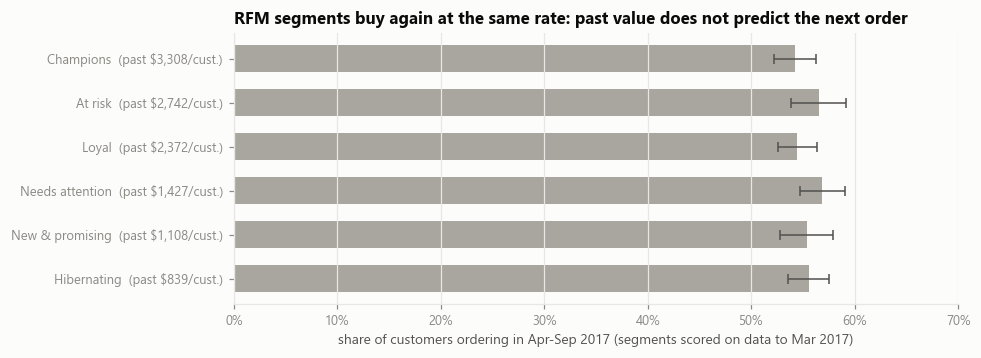

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
v = val.sort_values("past_revenue_per_customer")
y = np.arange(len(v))
ax.barh(y, v.share_ordering_next_6m, color=style.GREY, height=0.6)
ax.errorbar(v.share_ordering_next_6m, y, xerr=[v.share_ordering_next_6m - v.ci_low, v.ci_high - v.share_ordering_next_6m],
            fmt="none", ecolor=style.INK_2, capsize=3, lw=1)
ax.set_yticks(y, [f"{s}  (past ${p:,.0f}/cust.)" for s, p in zip(v.rfm_segment, v.past_revenue_per_customer)], fontsize=8.5)
ax.set_xlim(0, 0.7); style.pct(ax, axis="x"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("share of customers ordering in Apr-Sep 2017 (segments scored on data to Mar 2017)")
ax.set_title("RFM segments buy again at the same rate: past value does not predict the next order")
style.save(fig, "q3_rfm_validation")
plt.show()

## 4. What is a point of repeat rate worth?
Since every customer behaves alike, the retention lever is the base repeat rate itself. Value of +1 point of
monthly repeat rate over the last 12 months of the window (October 2016 to September 2017):

In [8]:
last12 = q("""
    WITH active AS (
        SELECT customer_key, CAST(date_trunc('month', order_date) AS DATE) AS m,
               sum(item_total) AS rev, sum(profit) AS prof
        FROM fact_order_items
        WHERE is_valid_order AND order_date >= DATE '2016-10-01' AND order_date < DATE '2017-10-01'
        GROUP BY 1, 2
    ), base AS (
        SELECT count(DISTINCT customer_key) AS customers FROM fact_order_items
        WHERE is_valid_order AND order_date < DATE '2016-10-01'
    )
    SELECT (SELECT customers FROM base) AS customer_base,
           count(*) FILTER (WHERE customer_key IN (SELECT customer_key FROM fact_order_items
                                                   WHERE is_valid_order AND order_date < DATE '2016-10-01')) AS repeat_customer_months,
           avg(rev) AS revenue_per_active_month, avg(prof) AS profit_per_active_month
    FROM active
""", con).iloc[0]
monthly_repeat_rate = last12.repeat_customer_months / (last12.customer_base * 12)
value_per_pt_rev = last12.customer_base * 0.01 * 12 * last12.revenue_per_active_month
value_per_pt_profit = last12.customer_base * 0.01 * 12 * last12.profit_per_active_month
print(f"Existing customers (acquired before Oct 2016): {int(last12.customer_base):,}; monthly repeat rate "
      f"{monthly_repeat_rate:.1%}; revenue per active customer-month ${last12.revenue_per_active_month:,.0f}")
print(f"+1 pt of monthly repeat rate ≈ ${value_per_pt_rev:,.0f} revenue / ${value_per_pt_profit:,.0f} profit per year")

Existing customers (acquired before Oct 2016): 11,706; monthly repeat rate 12.5%; revenue per active customer-month $586
+1 pt of monthly repeat rate ≈ $823,147 revenue / $99,987 profit per year


## Finding → number → decision

In [9]:
s = seg.set_index("rfm_segment")
vv = val.set_index("rfm_segment")
findings = {
    "customers": len(rfm),
    "segments": seg.to_dict(orient="records"),
    "champions_customer_share": s.loc["Champions", "customer_share"],
    "champions_revenue_share": s.loc["Champions", "revenue_share"],
    "month3_retention": m3.month3_retention, "month3_ci": list(m3_ci),
    "month3_customers": int(m3.cohort_customers),
    "retention_slope_pts_per_month": slope.params["month_index"] * 100, "retention_slope_p": slope.pvalues["month_index"],
    "next6m_share_by_segment": vv.share_ordering_next_6m.to_dict(),
    "next6m_min": val.share_ordering_next_6m.min(), "next6m_max": val.share_ordering_next_6m.max(),
    "segment_chi2_p": p_seg, "auc": aucs,
    "customer_base_existing": int(last12.customer_base), "monthly_repeat_rate": monthly_repeat_rate,
    "revenue_per_active_month": last12.revenue_per_active_month,
    "value_per_repeat_pt_revenue": value_per_pt_rev, "value_per_repeat_pt_profit": value_per_pt_profit,
}
save_findings("q3", findings)
display(Markdown(f"""
**Finding.** RFM describes the past but does not predict the future here. Champions are {s.loc['Champions', 'customer_share']:.0%}
of customers and {s.loc['Champions', 'revenue_share']:.0%} of revenue, yet scored on data to March 2017 they were no more likely to order in
the next six months than Hibernating customers ({vv.loc['Champions', 'share_ordering_next_6m']:.1%} vs {vv.loc['Hibernating', 'share_ordering_next_6m']:.1%};
chi-square across all six segments p = {p_seg:.2f}; AUC of recency {aucs['recency (more recent = higher)']:.2f}, frequency {aucs['frequency']:.2f},
monetary {aucs['monetary']:.2f}, where 0.5 is a coin flip). Cohorts retain at a flat **{m3.month3_retention:.1%}** in month 3
(95% CI {m3_ci[0]:.1%} to {m3_ci[1]:.1%}) with no decay over 24 months.

**Number.** Each customer orders in about {monthly_repeat_rate:.0%} of months whatever their history. One extra point of
monthly repeat rate across the {int(last12.customer_base):,} existing customers is worth about **${value_per_pt_rev / 1e3:,.0f}k revenue
(${value_per_pt_profit / 1e3:,.0f}k profit) a year**.

**Decision.** Don't spend retention money on RFM-targeted win-back lists: targeting by past value would not reach
customers any likelier to come back. Fund one broad retention offer as a randomised holdout test, and scale it
only if its lift in monthly repeat rate covers its cost at about ${value_per_pt_profit / 1e3:,.0f}k profit per point.
"""))


**Finding.** RFM describes the past but does not predict the future here. Champions are 19%
of customers and 30% of revenue, yet scored on data to March 2017 they were no more likely to order in
the next six months than Hibernating customers (54.2% vs 55.5%;
chi-square across all six segments p = 0.45; AUC of recency 0.49, frequency 0.50,
monetary 0.49, where 0.5 is a coin flip). Cohorts retain at a flat **12.7%** in month 3
(95% CI 12.1% to 13.3%) with no decay over 24 months.

**Number.** Each customer orders in about 13% of months whatever their history. One extra point of
monthly repeat rate across the 11,706 existing customers is worth about **$823k revenue
($100k profit) a year**.

**Decision.** Don't spend retention money on RFM-targeted win-back lists: targeting by past value would not reach
customers any likelier to come back. Fund one broad retention offer as a randomised holdout test, and scale it
only if its lift in monthly repeat rate covers its cost at about $100k profit per point.
